# 00b · Building overview (all floors, cleaned data)

The basic exploratory analysis that each floor's own notebook used to repeat, done once here on the shared cleaned
data so that all the numbers agree. Read `00a_data_quality` first: the gaps it lists appear here as breaks in the
lines, never as zeros. What is unusual about each individual floor is covered in `00c_floor_profiles`.

| § | Question |
|---|---|
| 1 | Where does the energy go? |
| 2 | How does daily energy change over the 18 months? |
| 3 | What does a typical day look like on workdays, weekends and holidays? |
| 4 | Carpet plot: every hour of one floor at a glance |
| 5 | How cool are the zones when they are occupied and the AC is on? |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # viz falls back from Segoe UI quietly

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)
from sbanalytics import baseline as B, kpis as K, config as C

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
print(f"{len(h):,} zone-hours, {fh.floor.nunique()} floors, {fh.ts.min():%Y-%m-%d} to {fh.ts.max():%Y-%m-%d}; "
      f"{fh.ok.mean():.1%} of floor-hours pass the usable-hour gate")

434,808 zone-hours, 7 floors, 2018-07-01 to 2019-12-31; 93.7% of floor-hours pass the usable-hour gate


## 1 · Where the energy goes

How each floor's energy splits between AC, lighting and plug loads over the whole record (usable hours only).

,ac MWh,light MWh,plug MWh
floor,,,
1,435.5,722.5,239.5
2,282.1,56.8,20.8
3,162.2,69.9,16.5
4,179.8,56.4,27.7
5,178.0,71.6,21.6
6,146.7,82.7,19.1
7,293.0,72.7,9.0


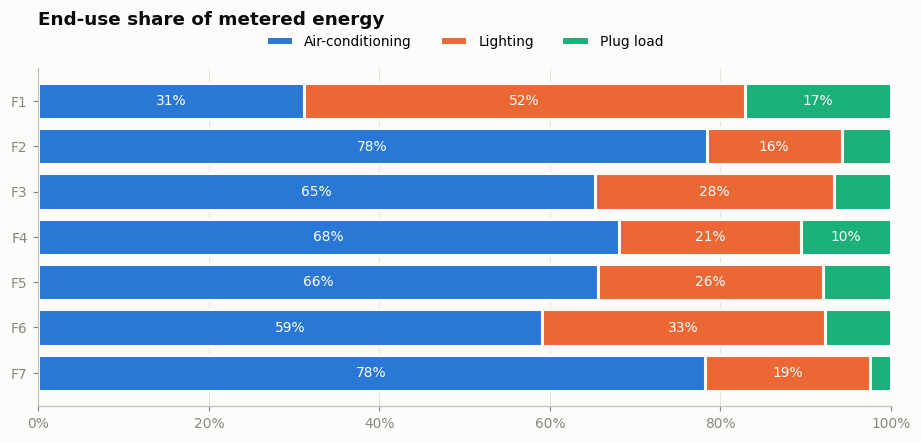

In [3]:
eu = fh[fh.ok].groupby("floor")[["ac_kwh", "light_kwh", "plug_kwh"]].sum()
share = eu.div(eu.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
left = np.zeros(len(share))
for col, key in zip(share.columns, ("ac", "light", "plug")):
    ax.barh([f"F{f}" for f in share.index], share[col], left=left, color=viz.END_USE_COLORS[key],
            label=viz.END_USE_LABELS[key], edgecolor=viz.SURFACE, linewidth=2)
    for i, (l, v) in enumerate(zip(left, share[col])):
        if v > 0.08:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)
    left += share[col].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02)); ax.grid(axis="y", visible=False)
ax.set_title("End-use share of metered energy", pad=28)
(eu / 1000).round(1).rename(columns=lambda c: c.replace("_kwh", " MWh"))

AC is the largest use of energy on every floor except F1, where lighting comes first. This fits with F1 not being an
office floor (00a §5). F1 also uses about four times as much energy as any other floor. Because floor areas are
unknown, notebooks `01`–`06` never compare absolute kWh between floors; they compare ratios instead.

## 2 · Daily energy over time

Daily total per floor (usable days only, smoothed with a 7-day rolling average). **Gaps are outages, not zero use.**
The shaded bands are the outages listed in 00a §2.

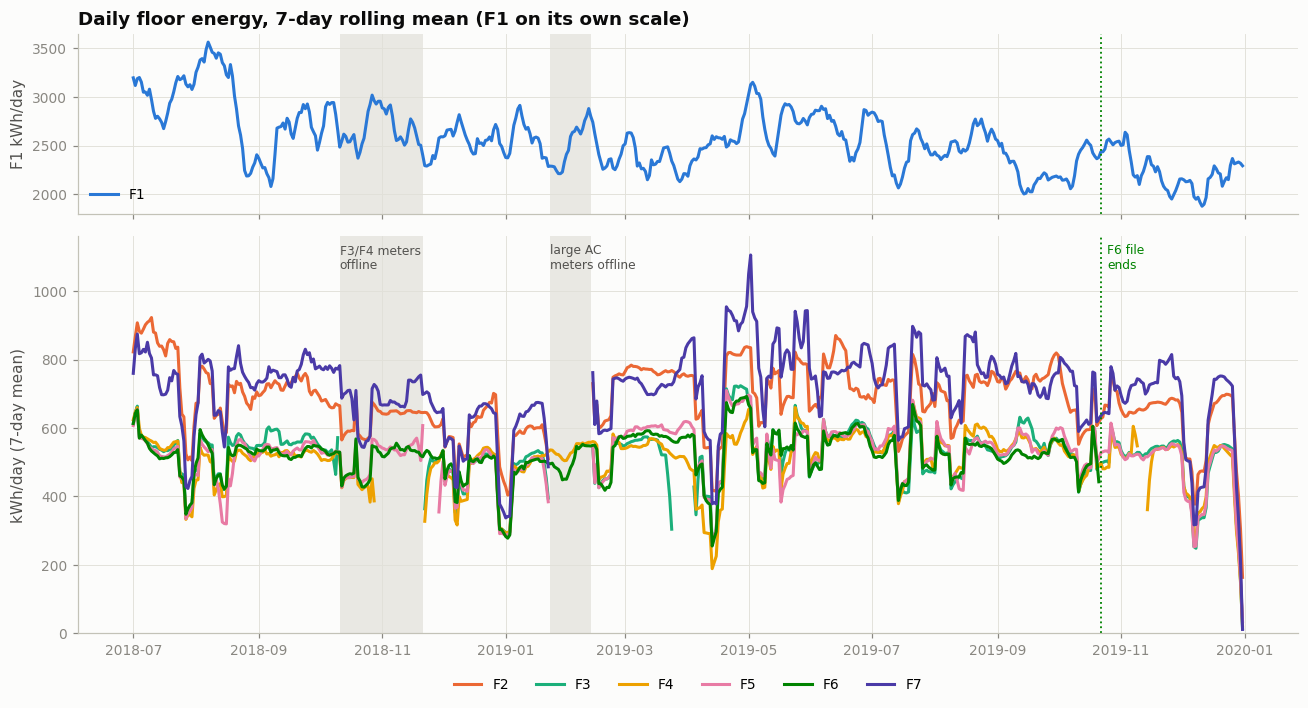

In [4]:
fig, (ax1, ax) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 2.2]})
for f, g in fd.groupby("floor"):
    g = g.set_index("day")
    s = g.total_kwh.where(g.ok).rolling(7, min_periods=4, center=True).mean()
    (ax1 if f == 1 else ax).plot(s.index, s, color=viz.FLOOR_COLORS[f], label=f"F{f}")
for a in (ax1, ax):
    for d0, d1 in [("2018-10-11", "2018-11-21"), ("2019-01-23", "2019-02-12")]:
        a.axvspan(pd.Timestamp(d0), pd.Timestamp(d1), color=viz.GRID, alpha=0.7, lw=0)
    a.axvline(pd.Timestamp("2019-10-22"), color=viz.FLOOR_COLORS[6], ls=":", lw=1.2)
ax.set_ylim(0, None)
for d0, lab in [("2018-10-11", "F3/F4 meters\noffline"), ("2019-01-23", "large AC\nmeters offline")]:
    ax.text(pd.Timestamp(d0), ax.get_ylim()[1] * 0.98, lab, fontsize=8, color=viz.INK_2, va="top")
ax.text(pd.Timestamp("2019-10-25"), ax.get_ylim()[1] * 0.98, "F6 file\nends", fontsize=8, color=viz.FLOOR_COLORS[6], va="top")
ax1.set_title("Daily floor energy, 7-day rolling mean (F1 on its own scale)")
ax1.set_ylabel("F1 kWh/day"); ax.set_ylabel("kWh/day (7-day mean)")
ax1.legend(loc="lower left"); ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout();

F1 sits far above the office floors and falls gradually through 2019, partly because its zone 2 lighting halved in
Feb 2019 (see 00c, F1). The office floors all follow the same seasonal pattern: highest in the hot season (Apr–May),
with dips over the year-end holidays and Songkran (Thai New Year, mid-April). While the large AC meters were offline
(Jan–Feb 2019), F2, F3, F5 and F7 disappear from the chart because those days do not have enough data to count as
usable. F4 and F6 keep reporting. F3 also disappears for a week in late March 2019, when its large AC meters dropped
out again (see the outage register in 00a).

## 3 · A typical day, by day type

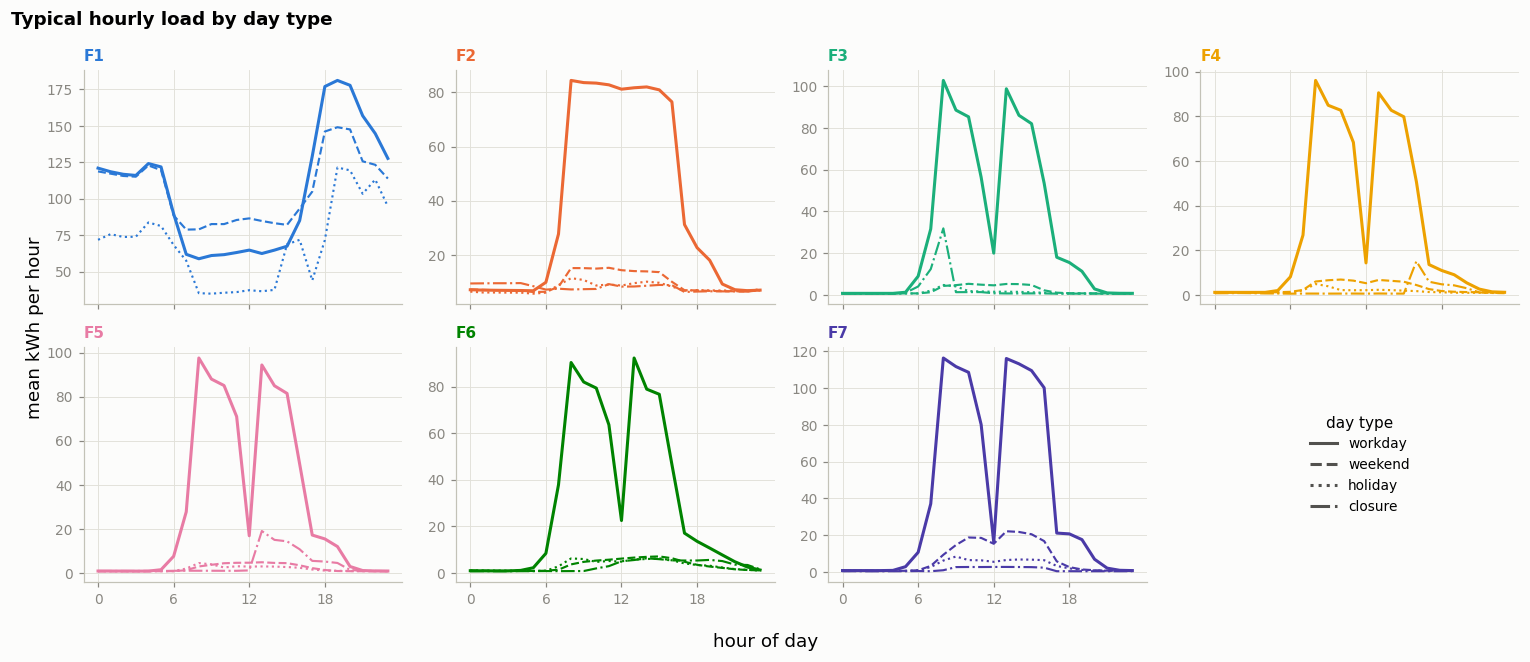

In [5]:
types = ["workday", "weekend", "holiday", "closure"]
prof = fh[fh.ok].groupby(["floor", "day_type", "hour"]).total_kwh.mean()
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
styles = {"workday": "-", "weekend": "--", "holiday": ":", "closure": "-."}
for ax, f in zip(axes.flat, C.FLOORS):
    for t in types:
        if (f, t) in prof.index:
            p = prof.loc[(f, t)]
            ax.plot(p.index, p, color=viz.FLOOR_COLORS[f], ls=styles[t], lw=2 if t == "workday" else 1.4, label=t)
    ax.set_title(f"F{f}", fontsize=10, color=viz.FLOOR_COLORS[f]); ax.set_xticks(range(0, 24, 6))
axes.flat[-1].axis("off")
handles = [plt.Line2D([], [], color=viz.INK_2, ls=styles[t], lw=2, label=t) for t in types]
axes.flat[-1].legend(handles=handles, loc="center", title="day type")
fig.supylabel("mean kWh per hour"); fig.supxlabel("hour of day")
fig.suptitle("Typical hourly load by day type", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

In [6]:
dt = D.load_day_types()
dt.pivot_table(index="floor", columns="day_type", values="date", aggfunc="count", fill_value=0)

day_type,closure,holiday,holiday_worked,weekend,workday
floor,,,,,
1,0,1,36,147,365
2,4,36,1,147,361
3,3,36,1,147,362
4,7,36,1,147,358
5,5,36,1,147,360
6,1,36,1,147,364
7,2,36,1,147,363


F2–F7 show a typical office pattern: load rises at 08:00, dips at lunchtime (except on F2) and drops around 16:30,
while weekends stay close to the floor's minimum load. F2 and F7 use noticeably more energy at weekends than the other
office floors, because their AC runs on some weekends (see 00c). F1 is the reverse: its load is lowest during working
hours.

*Closures* are workdays on which a floor used less than 30% of a normal workday's energy between 08:00 and 16:59.
*Worked holidays* are public holidays on which a floor used at least 70% of it. Labelling these days correctly stops
them from being reported as anomalies later. F1's 36 "worked holidays" reflect its unusual, non-office pattern of
use, not people working on holidays.

## 4 · Carpet plot (one floor)

Each pixel is one hour of the record, laid out by date and hour of day. Schedules, lunch breaks, weekends and outages
all stand out. Change `FLOOR` in the code to view a different floor.

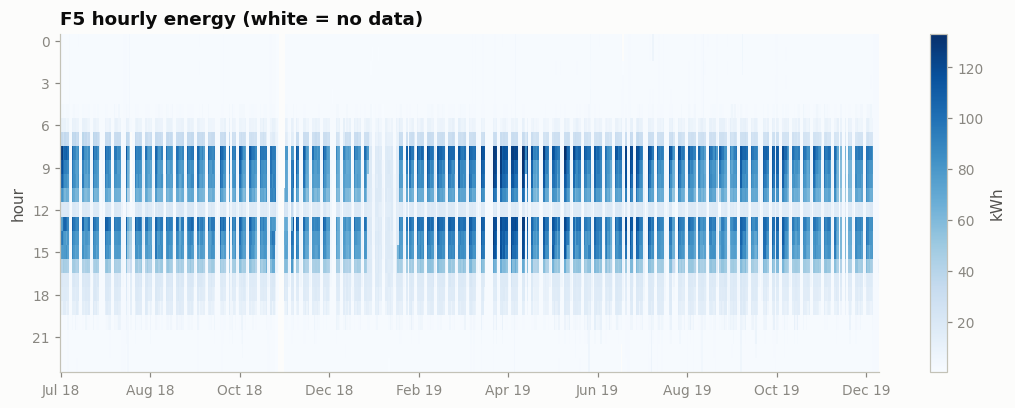

In [7]:
FLOOR = 5
g = fh[fh.floor == FLOOR]
carpet = g.pivot_table(index=g.ts.dt.normalize(), columns="hour", values="total_kwh", dropna=False)
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(carpet.T.to_numpy(), aspect="auto", cmap=viz.SEQUENTIAL, interpolation="nearest")
ax.set_yticks(range(0, 24, 3)); ax.set_ylabel("hour")
ticks = np.arange(0, len(carpet), 60)
ax.set_xticks(ticks, [carpet.index[i].strftime("%b %y") for i in ticks]); ax.grid(False)
fig.colorbar(im, ax=ax, label="kWh")
ax.set_title(f"F{FLOOR} hourly energy (white = no data)");

## 5 · Comfort in occupied, cooled hours

This section looks at workday hours inside each floor's AC schedule, with the AC running and a working sensor (at
least 30 minutes of readings in the hour). Only sensors that measure room air are included: F5 zone 1's sensor
measures the cold air coming out of the AC, so it is left out, and F1 has no sensors. The comfort band is 23–26 °C
(`registry.CONVENTIONS`). Because of the sensor blackout (00a §2), all of these hours fall in Jul to mid-Sep 2018 or
Mar–Dec 2019.

In [8]:
comfort = K.zone_comfort(h)
w = comfort.assign(wt=comfort.ac_kwh_in_window)
floor_share = (w.share_below_lo * w.wt).groupby(w.floor).sum() / w.wt.groupby(w.floor).sum()
print("Share of occupied, cooled hours below 23 °C (AC-energy weighted across zones):")
print("  " + ", ".join(f"F{f} {v:.0%}" for f, v in floor_share.items()))
comfort.round(2)

Share of occupied, cooled hours below 23 °C (AC-energy weighted across zones):
  F2 80%, F3 80%, F4 82%, F5 68%, F6 75%, F7 83%


,floor,zone,hours,mean_temp_c,share_below_lo,share_above_hi,cold_degree_hours,share_rh_above,ac_kwh_in_window
0,2,z1,2133,21.48,0.77,0.00,3593.74,0.45,62536.44
1,2,z2,2206,22.10,0.78,0.08,3210.41,0.94,63057.87
2,2,z4,1748,18.55,1.00,0.00,7784.48,0.99,14899.05
3,3,z1,1791,22.73,0.67,0.01,1261.73,0.19,37945.49
4,3,z2,1875,22.29,0.68,0.00,1805.45,0.12,30518.90
5,3,z4,1876,19.47,0.97,0.00,6660.10,0.92,33222.26
6,3,z5,1582,20.23,0.98,0.00,4401.31,0.96,12539.88
7,4,z1,1923,21.67,0.79,0.00,2982.89,0.72,41599.47
8,4,z2,1888,21.10,0.80,0.00,3869.17,1.00,28573.18
9,4,z4,1584,20.07,0.92,0.01,4830.50,0.53,30657.30


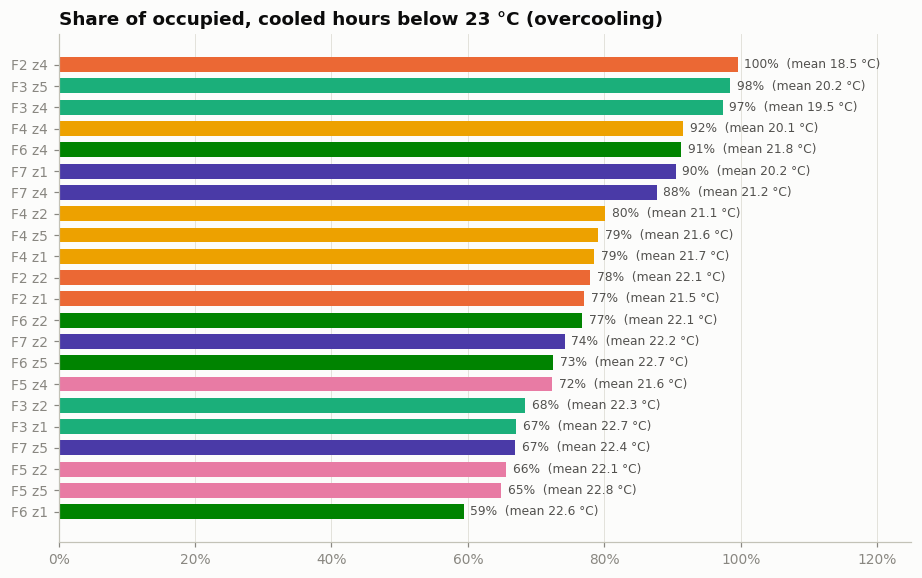

In [9]:
c = comfort.sort_values("share_below_lo")
fig, ax = plt.subplots(figsize=(10, 6))
labels = [f"F{f} {z}" for f, z in zip(c.floor, c.zone)]
ax.barh(labels, c.share_below_lo, color=[viz.FLOOR_COLORS[f] for f in c.floor], height=0.7)
for i, (v, t) in enumerate(zip(c.share_below_lo, c.mean_temp_c)):
    ax.text(v + 0.01, i, f"{v:.0%}  (mean {t:.1f} °C)", va="center", fontsize=8, color=viz.INK_2)
ax.set_xlim(0, 1.25); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.grid(axis="y", visible=False)
ax.set_title("Share of occupied, cooled hours below 23 °C (overcooling)");

**Overcooling is the clearest pattern in the building.** On every office floor, between two-thirds and four-fifths of
occupied, cooled hours are below 23 °C, the bottom of the comfort band (68–83% when weighted by AC energy, lowest on F5
and highest on F7). Some zones average only 18.5–20 °C (F2 zone 4, F3 zone 4, F7 zone 1). This is the evidence behind
the recommendation in `06` to raise AC setpoints.

**Next:** `00c_floor_profiles` covers what each floor owner found that only their floor shows.